# Stochastic Volatility Models

## Workflow overview

This notebook compares simulated prices and instantaneous relative volatility under three stochastic volatility models. Heston returns variance, and SABR returns a diffusion level. The plots convert both to annualized relative volatility.


### Execution environment

Run this notebook from the repository root. In a fresh environment, run `python -m pip install "riskoptima==2.8.5"` before execution. The simulations are seeded and require no market data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from riskoptima import RiskOptima
print(RiskOptima.VERSION)
from riskoptima.branding import add_riskoptima_signature

2.8.5


In [2]:
def plot_simulations():
        """
        Runs simulations for all three models and plots their paths.
        """
        np.random.seed(21)
        S_HW, sigma_HW = RiskOptima.simulate_hull_white()
        S_Heston, heston_variance = RiskOptima.simulate_heston(sigma0=0.2**2, theta=0.2**2, random_state=22)
        initial_forward, beta = 100, 0.5
        initial_level = 0.2 * initial_forward ** (1 - beta)
        F_SABR, sabr_level = RiskOptima.simulate_sabr(initial_forward, initial_level, beta=beta, random_state=23)
        sabr_relative_vol = sabr_level * np.power(
            F_SABR, beta - 1, out=np.full_like(F_SABR, np.nan), where=F_SABR > 0
        )

        plt.figure(figsize=(12, 6))
        plt.plot(S_HW, label="Hull-White Asset Price", linestyle='dashed')
        plt.plot(S_Heston, label="Heston Asset Price", linestyle='dotted')
        plt.plot(F_SABR, label="SABR Forward Price", linestyle='solid')
        plt.legend()
        plt.title("Simulated Price Paths for Different Stochastic Volatility Models")
        plt.xlabel("Time Steps")
        plt.ylabel("Price")
        add_riskoptima_signature(plt.gca())
        plt.show()

        plt.figure(figsize=(12, 6))
        plt.plot(sigma_HW, label="Hull-White Volatility", linestyle='dashed')
        plt.plot(np.sqrt(heston_variance), label="Heston Volatility", linestyle='dotted')
        plt.plot(sabr_relative_vol, label="SABR Relative Volatility", linestyle='solid')
        plt.legend()
        plt.title("Simulated Volatility Paths for Different Stochastic Volatility Models")
        plt.xlabel("Time Steps")
        plt.ylabel("Annualized relative volatility")
        add_riskoptima_signature(plt.gca())
        plt.show()

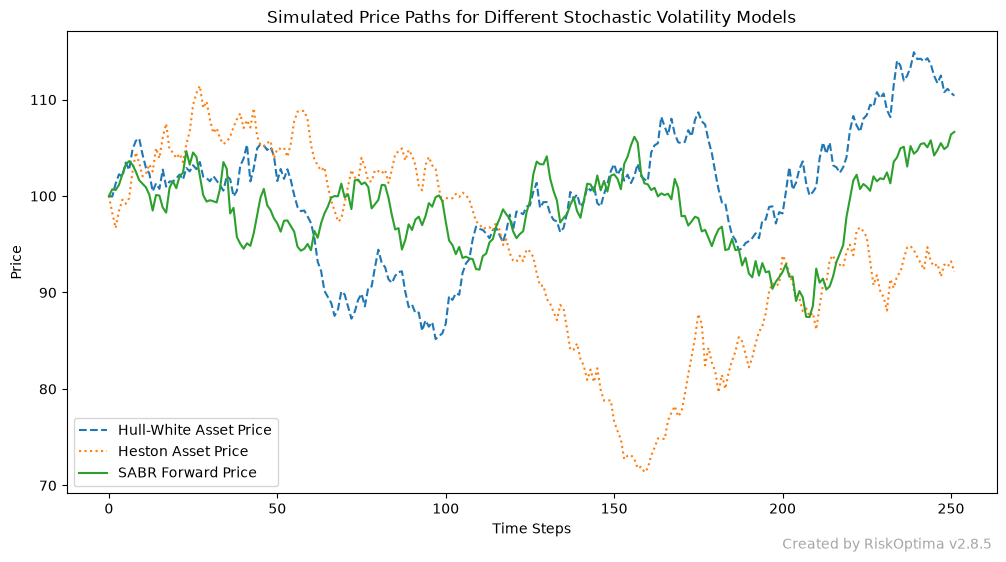

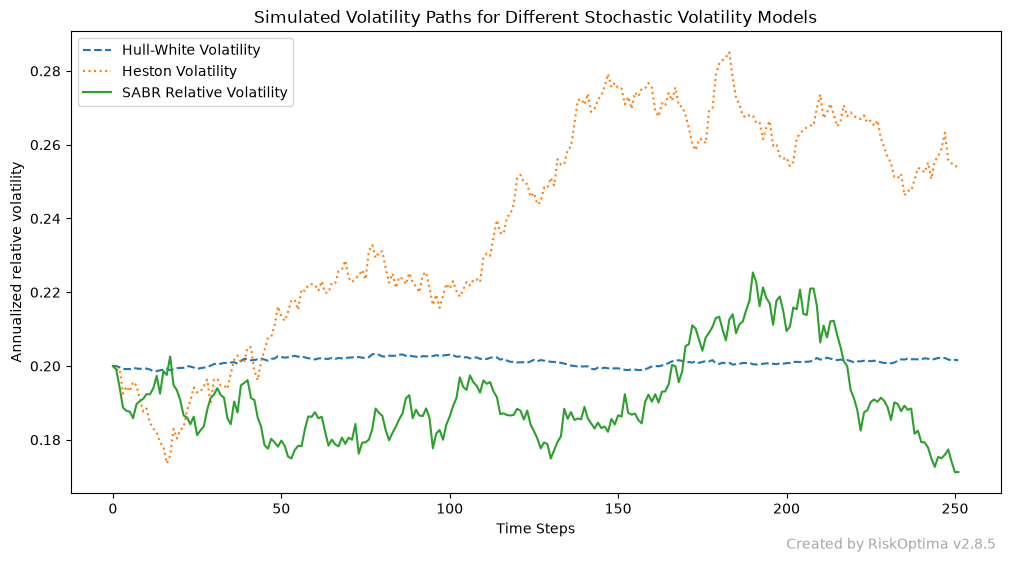

In [3]:
plot_simulations()